# Linear Regression with RMSProp Batch Gradient Descent

This notebook demonstrates how to perform linear regression using **RMSProp (Root Mean Square Propagation) batch gradient descent** on synthetic data. We'll walk through each part of the code step-by-step to understand the concepts involved.

#### Import Required Libraries

- **NumPy** is used for numerical operations and handling arrays.
- **Matplotlib** is for plotting graphs to visualize results.
- **TQDM** provides a progress bar for loops.
- **Scikit-learn** is used for calculating the R² score, which evaluates our model.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

pbar_format = "{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]" 

## 1. Helper Function for all GD

### Generate Synthetic Data

We create a function to generate synthetic data that follows a linear relationship.

- **Parameters**:
  - `n`: Number of data points.
  - `bias`: Intercept of the line.
  - `weight`: Slope of the line.
- **Output**: An array containing features and labels.

In [2]:
def synthetic_data(n=100, bias=5, weight=2):

    np.random.seed(42)
    torch.manual_seed(42)
    # Generate synthetic data (linear relationship with some noise)
    bias = 5
    weight = 2
    noise = np.random.randn(n)

    features = np.random.rand(n, 1) * 10
    labels = bias + weight * features.flatten() + noise  # Linear relation with noise

    data = np.hstack((features, labels.reshape(-1, 1)))
    return data

### Visualizing Results

This function will create plots for:
- Loss over epochs
- Values of model parameters (weights)

In [3]:
def plot_results(weights_history, cost_history, lr=None):
    fig, axes = plt.subplots(1, 3, figsize=(12, 15))

    # Plot Loss
    axes[0].plot(cost_history, label='Loss', color='blue')
    axes[0].set_title(f'Loss over Epochs (LR={lr})')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].grid(True)
    axes[0].legend()

    weights_history = np.array(weights_history)

    # Plot Weight 1 (bias)
    axes[1].plot(weights_history[:, 0], label='Weight 1 (bias)', color='green')
    axes[1].set_title(f'Weight 1 (bias) over Epochs (LR={lr})')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Weight 1 Value')
    axes[1].grid(True)
    axes[1].legend()

    # Plot Weight 2
    axes[2].plot(weights_history[:, 1], label='Weight 2', color='orange')
    axes[2].set_title(f'Weight 2 over Epochs (LR={lr})')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Weight 2 Value')
    axes[2].grid(True)
    axes[2].legend()

    plt.tight_layout()
    plt.show()

### Evaluate the Model

We define a function to evaluate the model's performance using the R² score:

In [4]:
from sklearn.metrics import r2_score

def evaluate_model(X, y, theta):
    predictions = X @ theta
    return r2_score(y, predictions)

### (optional) Use Decorators to Display Pretty Report after Training

In [5]:
def report_decorator(func):
    def wrapper(*args, **kwargs):

        result = func(*args, **kwargs)
        epoch, weights_history, cost_history, r2 = result

        print("="*60)
        print(" "*20, "Final Training Report")
        print("="*60)
        print(f"🟢 Total Epochs Run : {epoch+1}")
        print(f"🟢 Final MSE        : {cost_history[-1]:.3f}")
        print(f"🟢 Final R-square   : {r2:.3f}")
        print(f"🟢 Final Weights    : [{', '.join(f'{float(w):.4f}' for w in weights_history[-1].flatten())}]")
        print("="*60)

        return result

    return wrapper

### (optional) Use Decorators to Calculate Time Duration of the Training

In [6]:
import time

def time_decorator(func):
    def training(*args, **kwargs):
        start_time = time.time()  # Start time
        result = func(*args, **kwargs)  # Call the function
        end_time = time.time()  # End time
        print(f"Time taken for {func.__name__}: {end_time - start_time:.4f} seconds")
        return result
    return training

## 2. RMSProp Batch Gradient Descent Using Python

The `RMSProp_python` function implements the Root Mean Square Propagation (RMSProp) algorithm using **Python** to optimize the model parameters.

### Key Changes from BGD to RMSProp

- **Added Decay Rate (`beta`)**: Introduced `beta` (typically `0.9`) to maintain an exponentially decaying average of squared gradients.
- **Added Smoothing Term (`epsilon`)**: Introduced `epsilon` (`1e-8`) to avoid division by zero.
- **Updated Weights Using Moving Average of Squared Gradients**: Scales the learning rate adaptively for each parameter using the root mean square of recent gradients.

### Key Steps
1. **Initialize Parameters**: Set initial weights (`theta`) randomly and moving average of squared gradients (`v_t`) to zero.
2. **Predict Output**: Compute predictions based on current weights.
3. **Calculate Loss**: Use Mean Squared Error (MSE) as the loss function.
4. **Compute Gradients**: Calculate the gradient of the loss with respect to the weights.
5. **Update Squared Gradient Moving Average**:
   `v_t = beta * v_t + (1 - beta) * (gradients ** 2)`
6. **Update Weights**:
   `theta -= (learning_rate / (np.sqrt(v_t) + epsilon)) * gradients`

In [7]:
@time_decorator
@report_decorator
def RMSProp_python(X, y, learning_rate=0.01, epochs=10000, beta=0.9, epsilon=1e-8, tolerance=1e-3):

    # Step 1: Add bias term to feature matrix (X)
    X_b = np.c_[np.ones((X.shape[0], 1)), X]  # Add a column of 1s for bias (theta_0)

    # Step 2: Initialize parameters (theta) randomly
    np.random.seed(42)
    theta = np.random.randn(2, 1)  # 2 parameters: bias (theta_0) and weight (theta_1)

    v_t = np.zeros_like(theta)

    cost_history = []
    weights_history = []

    m = len(X_b)  # Number of samples

    pbar = tqdm(range(epochs), bar_format=pbar_format)

    for epoch in pbar:
        # Step 3: Compute predictions
        predictions = X_b @ theta

        # Step 4: Compute loss (Mean Squared Error)
        loss = np.mean((predictions - y.reshape(-1, 1)) ** 2)
        cost_history.append(loss)
        weights_history.append(theta.copy())

        # Calculate R2 score
        r2 = evaluate_model(X_b, y, theta)

        # Step 5: Compute gradient
        gradients = (2/m) * X_b.T @ (predictions - y.reshape(-1, 1))

        # Step 6: Update moving average of squared gradients & Update parameters (theta)
        v_t = beta * v_t + (1 - beta) * (gradients ** 2)
        theta -= (learning_rate / (np.sqrt(v_t) + epsilon)) * gradients

        # Progress bar update
        pbar.set_description(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss:.6f} - r2: {r2:.3f} - Weights: {theta.flatten()}")

        # Stop condition: check if loss change is below tolerance
        if epoch > 0 and abs(cost_history[-2] - cost_history[-1]) < tolerance:
            print(f"\nConvergence reached at epoch {epoch+1}.")
            break

    return epoch, weights_history, cost_history, r2

In [8]:
# Generate 50 synthetic data points
data = synthetic_data(n=50, bias=5, weight=2)
X, y = data[:, :-1], data[:, -1]
print(f"X: {X}\n \n y: {y}")

X: [[1.40924225]
 [8.02196981]
 [0.74550644]
 [9.86886937]
 [7.72244769]
 [1.98715682]
 [0.05522117]
 [8.15461428]
 [7.06857344]
 [7.29007168]
 [7.71270347]
 [0.74044652]
 [3.58465729]
 [1.1586906 ]
 [8.63103426]
 [6.23298127]
 [3.30898025]
 [0.6355835 ]
 [3.10982322]
 [3.25183322]
 [7.29606178]
 [6.37557471]
 [8.87212743]
 [4.72214925]
 [1.19594246]
 [7.13244787]
 [7.60785049]
 [5.61277198]
 [7.7096718 ]
 [4.93795596]
 [5.22732829]
 [4.27541018]
 [0.25419127]
 [1.07891427]
 [0.31429186]
 [6.36410411]
 [3.14355981]
 [5.08570691]
 [9.07566474]
 [2.49292229]
 [4.10382923]
 [7.55551139]
 [2.28798165]
 [0.7697991 ]
 [2.89751453]
 [1.61221287]
 [9.29697652]
 [8.0812038 ]
 [6.33403757]
 [8.7146059 ]]
 
 y: [ 8.31519865 20.90567531  7.13870141 26.26076859 20.21074201  8.74017667
  6.68965516 22.0766633  18.66767249 20.1227034  19.96198924  6.01516328
 12.41127684  5.40410095 20.53715068 16.90367501 10.60512938  6.58541434
 10.31162236 10.09136274 21.05777234 17.52537313 22.81178306 13.0195503

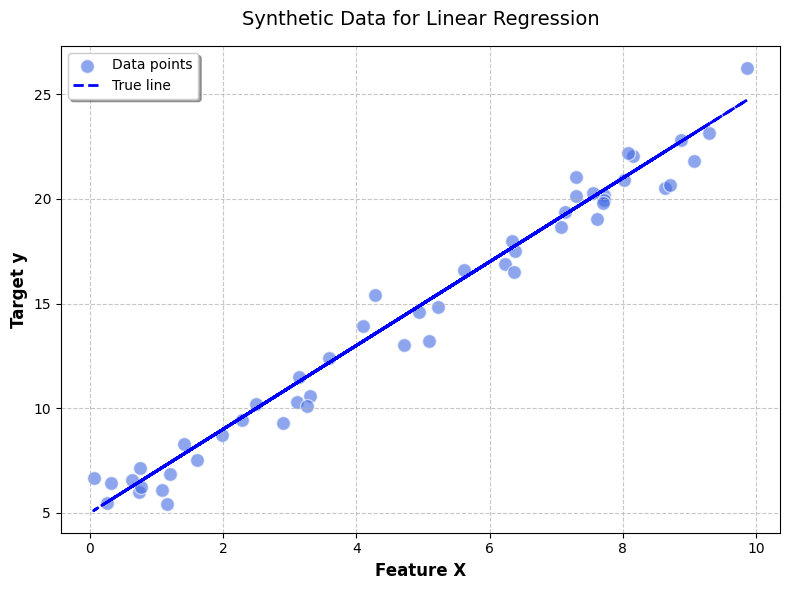

In [9]:
# Create a beautiful visualization of the synthetic data
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='royalblue', alpha=0.6, s=100, label='Data points', edgecolor='white')
plt.plot(X, 2 * X + 5, color='blue', linewidth=2, linestyle='--', label='True line')

# Customize the plot appearance
plt.xlabel('Feature X', fontsize=12, fontweight='bold')
plt.ylabel('Target y', fontsize=12, fontweight='bold')
plt.title('Synthetic Data for Linear Regression', fontsize=14, pad=15)

# Add grid and style the legend
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(frameon=True, fancybox=True, shadow=True, fontsize=10)

plt.tight_layout()
plt.show()

Epoch [452/10000] - Loss: 0.870663 - r2: 0.976 - Weights: [4.58801238 2.0203905 ]:    5%|██        | 452/10000 [00:00<00:00, 26500.59it/s]

Convergence reached at epoch 452.
                     Final Training Report
🟢 Total Epochs Run : 452
🟢 Final MSE        : 0.871
🟢 Final R-square   : 0.976
🟢 Final Weights    : [4.5836, 2.0314]
Time taken for RMSProp_python: 0.0171 seconds


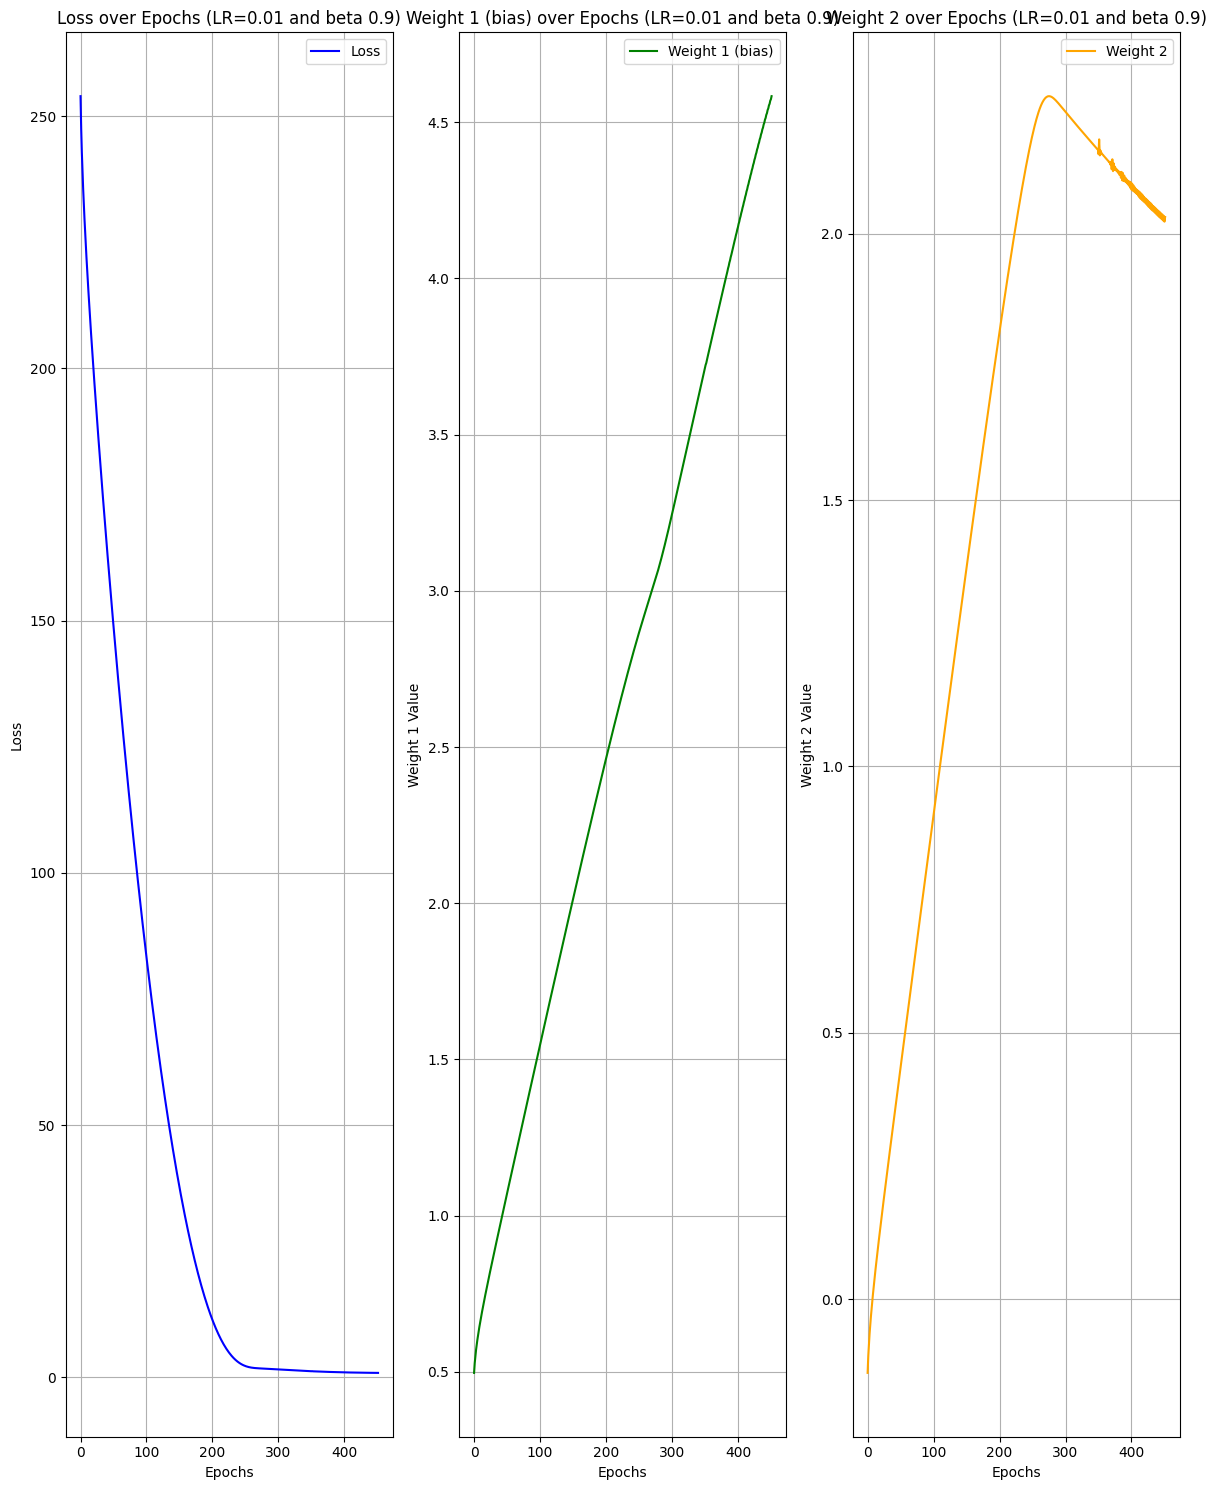

In [10]:
# Initialize hyperparameters
lr = 0.01
b = 0.9  # change beta and try

# Run RMSProp GD
_, weights_history, cost_history, r2 = RMSProp_python(X, y, learning_rate=lr, beta=b)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr} and beta {b}")

### Use Large Learning Rate

Epoch [93/10000] - Loss: 0.855435 - r2: 0.976 - Weights: [4.75168144 2.00083894]:    1%|██        | 93/10000 [00:00<00:00, 15265.15it/s]

Convergence reached at epoch 93.
                     Final Training Report
🟢 Total Epochs Run : 93
🟢 Final MSE        : 0.855
🟢 Final R-square   : 0.976
🟢 Final Weights    : [4.7382, 2.0029]
Time taken for RMSProp_python: 0.0061 seconds


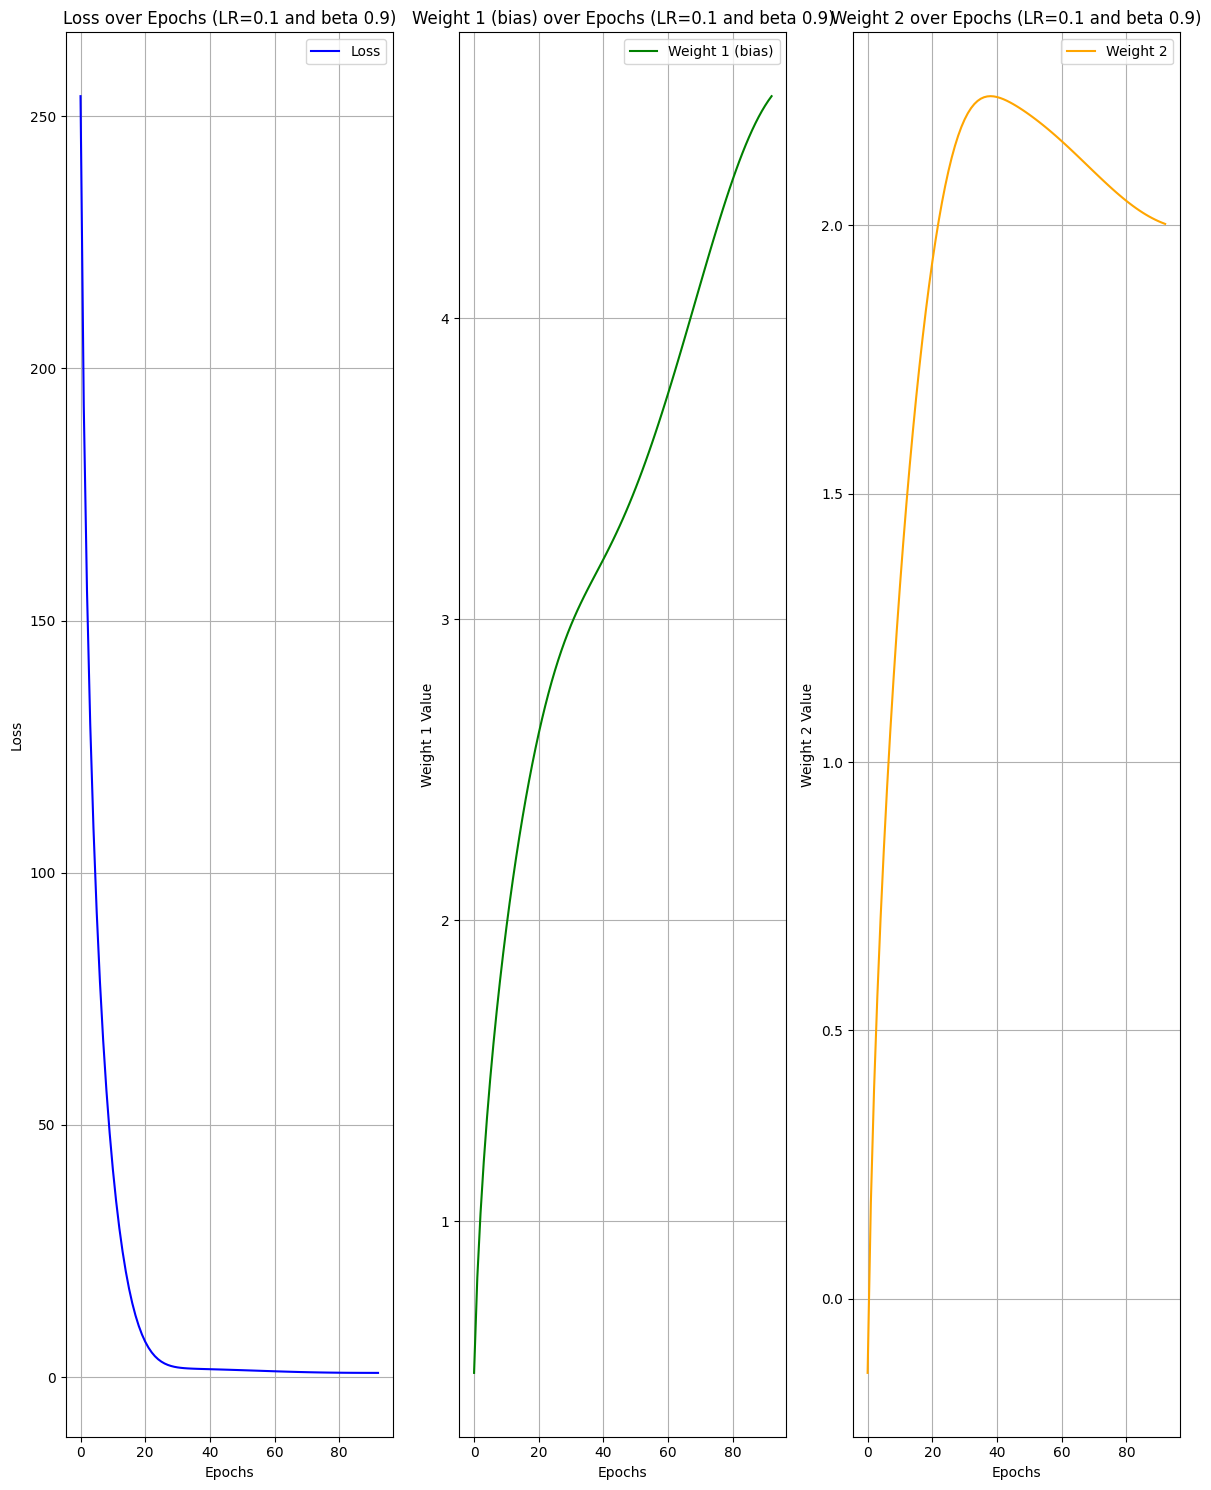

In [11]:
# Initialize hyperparameters
lr = 0.1
b = 0.9  # change beta and try

# Run RMSProp GD
_, weights_history, cost_history, r2 = RMSProp_python(X, y, learning_rate=lr, beta=b)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr} and beta {b}")

## 3. RMSProp Batch Gradient Descent Using PyTorch

In [12]:
@time_decorator
@report_decorator
def RMSProp_torch(X, y, learning_rate=0.01, epochs=10000, beta=0.9, epsilon=1e-8, tolerance=1e-3):

    # Step 1: Add bias term to feature matrix (X)
    X_b = torch.tensor(np.c_[np.ones((X.shape[0], 1)), X], dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

    # Step 2: Initialize parameters (theta) randomly
    torch.manual_seed(42)
    theta = torch.randn((2, 1), dtype=torch.float32, requires_grad=True)

    v_t = torch.zeros_like(theta)

    cost_history = []
    weights_history = []

    m = len(X_b)  # Number of samples

    pbar = tqdm(range(epochs), bar_format=pbar_format)

    for epoch in pbar:
        # Step 3: Compute predictions
        predictions = X_b @ theta

        # Step 4: Compute loss (Mean Squared Error)
        loss = torch.mean((predictions - y) ** 2)

        cost_history.append(loss.item())
        weights_history.append(theta.detach().numpy().copy())

        # Calculate R2 score
        r2 = evaluate_model(X_b.detach().numpy(), y.detach().numpy(), theta.detach().numpy())

        # Step 5: Compute gradient
        loss.backward()

        # Step 6: Update parameters (theta) using torch.no_grad()
        with torch.no_grad():
            gradients = theta.grad

            v_t = beta * v_t + (1 - beta) * (gradients ** 2)
            theta -= (learning_rate / (torch.sqrt(v_t) + epsilon)) * gradients

            # Zero gradients after updating
            theta.grad.zero_()

        # Progress bar update
        pbar.set_description(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss.item():.6f} - r2: {r2:.3f} - Weights: {theta.detach().numpy().flatten()}")

        # Stop condition: check if loss change is below tolerance
        if epoch > 0 and abs(cost_history[-2] - cost_history[-1]) < tolerance:
            print(f"\nConvergence reached at epoch {epoch+1}.")
            break

    return epoch, weights_history, cost_history, r2

Epoch [467/10000] - Loss: 0.870531 - r2: 0.976 - Weights: [4.589112  2.0202005]:    5%|██        | 467/10000 [00:00<00:00, 18222.53it/s]

Convergence reached at epoch 467.
                     Final Training Report
🟢 Total Epochs Run : 467
🟢 Final MSE        : 0.871
🟢 Final R-square   : 0.976
🟢 Final Weights    : [4.5847, 2.0313]
Time taken for RMSProp_torch: 0.0256 seconds


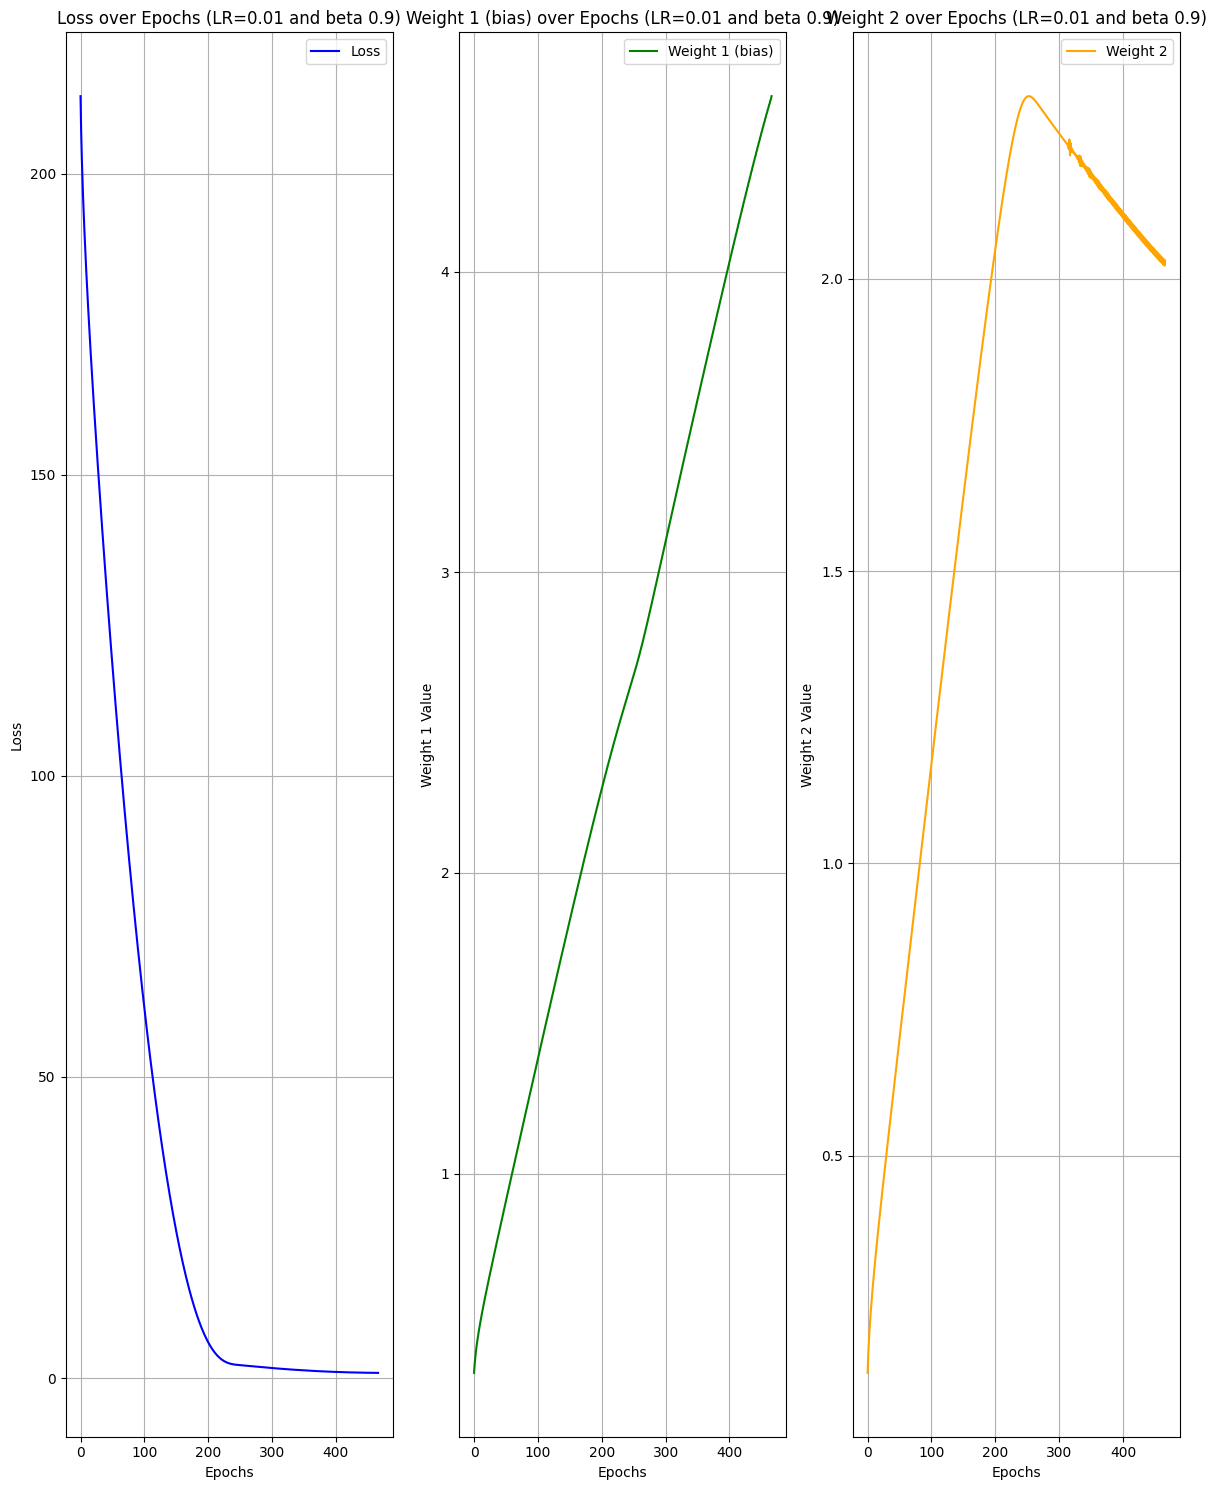

In [13]:
# Initialize hyperparameters
lr = 0.01
b = 0.9  # change beta and try

_, weights_history, cost_history, r2 = RMSProp_torch(X, y, learning_rate=lr, beta=b)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr} and beta {b}")

### Use Large Learning Rate

Epoch [90/10000] - Loss: 0.858246 - r2: 0.976 - Weights: [4.730893  2.0232406]:    1%|██        | 90/10000 [00:00<00:00, 21679.72it/s]

Convergence reached at epoch 90.
                     Final Training Report
🟢 Total Epochs Run : 90
🟢 Final MSE        : 0.858
🟢 Final R-square   : 0.976
🟢 Final Weights    : [4.7003, 2.0040]
Time taken for RMSProp_torch: 0.0042 seconds


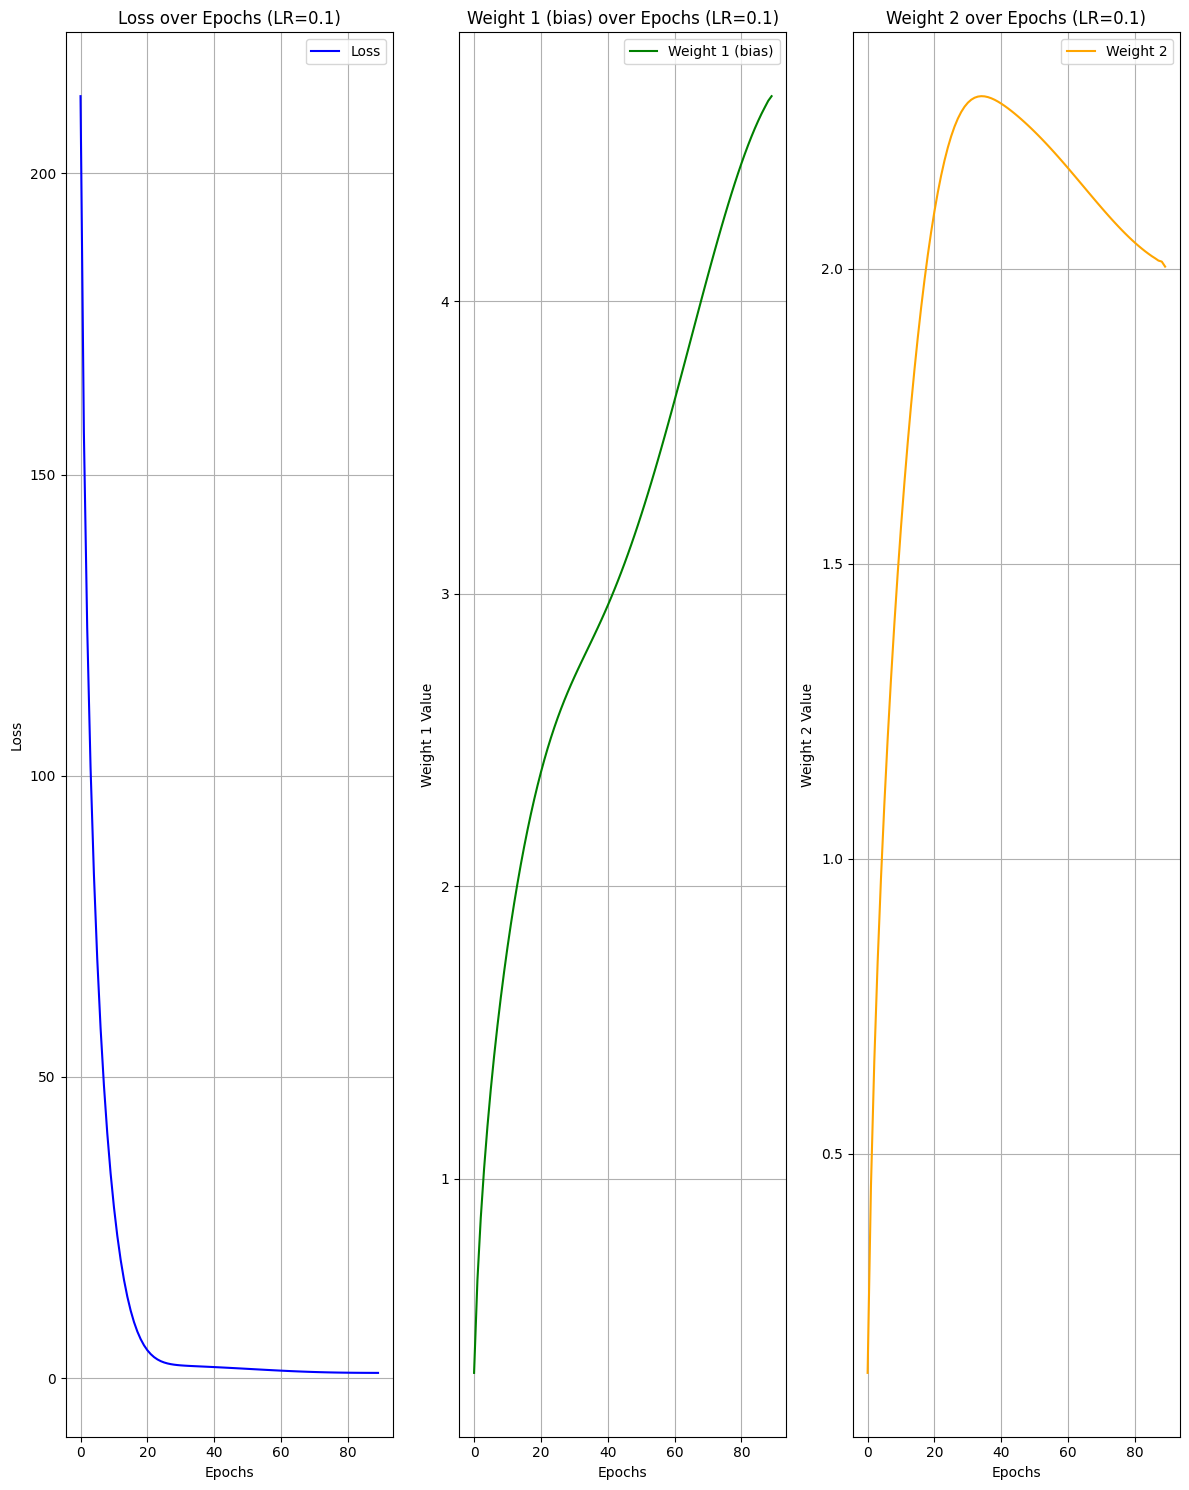

In [14]:
lr = 0.1
b = 0.9

_, weights_history, cost_history, r2 = RMSProp_torch(X, y, learning_rate=lr, beta=b)

# Plot results
plot_results(weights_history, cost_history, lr=lr)